<a href="https://colab.research.google.com/github/NikhilTheAi/NikhilTheAi-Machine-Learning-Experiments/blob/main/House_Price_Prediction_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction — Simple Linear Regression

### Dataset: Housing.csv

This notebook demonstrates the implementation of Simple Linear Regression to predict house prices using house area.

## Step 0: Install & Import Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## Step 1: Import the Data

In [4]:
# Load the dataset
df = pd.read_csv("/content/Housing.csv")

# Quick look at the data
print("Shape:", df.shape)
display(df.head())
display(df.describe())
df.info()

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


## Step 2: Basic Data Preprocessing

In [5]:
# Check info and missing values
print("\nMissing values per column:\n")
print(df.isnull().sum())

# Keep only the columns needed for Simple Linear Regression
data = df[['area', 'price']].copy()

# Remove missing and duplicate rows
data = data.dropna()
data = data.drop_duplicates()

print("\nFinal shape after cleaning:", data.shape)

# Display first five rows
data.head()


Missing values per column:

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Final shape after cleaning: (532, 2)


,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000


## Step 3: Visualize the Data (Scatter Plot)

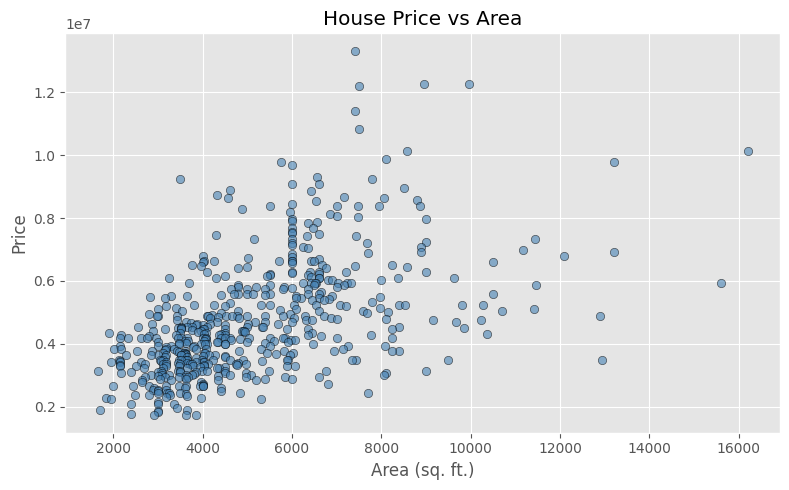

In [6]:
plt.figure(figsize=(8,5))

plt.scatter(
    data['area'],
    data['price'],
    color='steelblue',
    alpha=0.6,
    edgecolors='black'
)

plt.title("House Price vs Area")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

## Step 4: Train-Test Split

In [7]:
# Feature (Input)
X = data[['area']]

# Target (Output)
y = data['price']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nFirst five training feature values:")
display(X_train.head())

print("\nFirst five training target values:")
display(y_train.head())

Training samples: 425
Testing samples : 107

First five training feature values:


,area
306,4840
413,1950
458,3850
319,3000
145,5000



First five training target values:


,price
306,4165000
413,3430000
458,3115000
319,4060000
145,5600000


## Step 5: Train the Linear Regression Model

In [8]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## Step 6: Slope and Intercept

In [9]:
# Get slope and intercept
slope = model.coef_[0]
intercept = model.intercept_

print(f"Slope (coefficient): {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

print(f"\nEquation:")
print(f"Price = {slope:.4f} × Area + ({intercept:.4f})")

Slope (coefficient): 441.5876
Intercept: 2450352.7349

Equation:
Price = 441.5876 × Area + (2450352.7349)


## Step 7: Accuracy Metrics

In [10]:
# Predict on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 1,424,905.44
Mean Squared Error (MSE): 3,547,685,936,845.33
Root Mean Squared Error (RMSE): 1,883,530.18
R² Score: 0.2770


## Step 8: Visualize the Regression Line

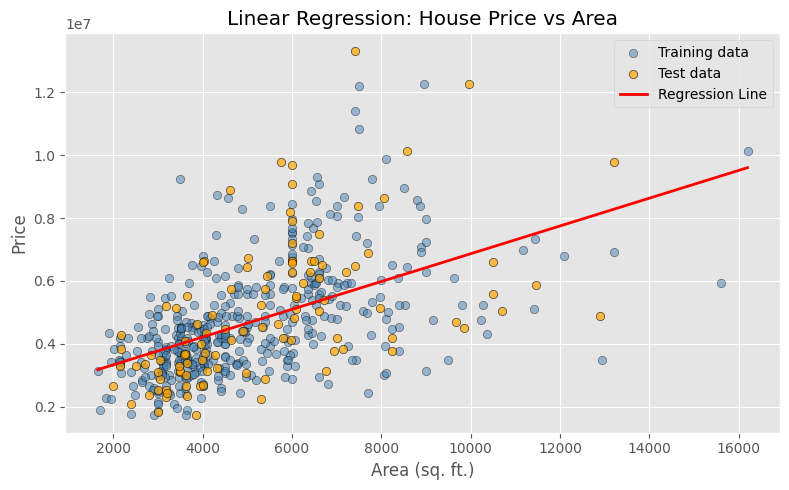

In [11]:
plt.figure(figsize=(8,5))

# Training data
plt.scatter(
    X_train,
    y_train,
    color='steelblue',
    alpha=0.5,
    edgecolor='k',
    label='Training data'
)

# Testing data
plt.scatter(
    X_test,
    y_test,
    color='orange',
    alpha=0.7,
    edgecolor='k',
    label='Test data'
)

# Regression line
x_range = np.linspace(data['area'].min(), data['area'].max(), 100).reshape(-1,1)
y_range_pred = model.predict(x_range)

plt.plot(
    x_range,
    y_range_pred,
    color='red',
    linewidth=2,
    label='Regression Line'
)

plt.title("Linear Regression: House Price vs Area")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price")

plt.legend()
plt.tight_layout()
plt.show()

## Step 9: Predict Price for a New House

In [12]:
def predict_price(area_value):
    input_df = pd.DataFrame([[area_value]], columns=['area'])
    predicted_price = model.predict(input_df)[0]
    return predicted_price

# Example
new_area = 3000

predicted = predict_price(new_area)

print(f"Predicted price for area = {new_area} sq. ft.: ₹{predicted:,.2f}")

Predicted price for area = 3000 sq. ft.: ₹3,775,115.53


# Summary

- Successfully loaded and preprocessed the Housing dataset.
- Built a Simple Linear Regression model using house area as the input feature.
- Evaluated the model using MAE, MSE, RMSE, and R² Score.
- Visualized the regression line.
- Predicted the price of a new house based on its area.